# LLM bee colony: local agents, hidden hive-state vectors

This notebook models a spatial beehive using design ideas from **TaskSelSim, ApisRAM, SIMBACA and Bee++**. The default colony has **50 adult agents, including one queen**, plus passive brood. In live mode, **every adult decision calls OpenAI `gpt-6-luna`**.

A separate observer records a **14-component vector immediately after every action attempt**. All components lie in **[0, 1]**, with higher values representing better conditions. Bees receive only local physical observations, their personal memory and nearby messages. They never receive the observer vector, its history or researcher scores.

**The saved execution is an offline demonstration, not an LLM result.** Set `MODE = "live"` below to use the requested model. See [MODEL_DESIGN.md](MODEL_DESIGN.md) for formulas, assumptions and precise source mapping. Keep `beehive_sim.py` alongside this notebook.

## 1. Imports

Install once if needed: `python3 -m pip install -r requirements.txt`. The engine itself uses only the Python standard library. The OpenAI SDK is imported only in live mode.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json
import math
import os

import matplotlib.pyplot as plt
from IPython.display import FileLink, Markdown, display
from beehive_sim import (
    Config, World, Observer, Simulation, OpenAIPolicy, OfflineDemoPolicy,
    VECTOR_NAMES, plot_hive, plot_transcript, weighted_research_score,
)


## 2. Adjustable experiment settings

Change `N_BEES` to adjust the adult population. With 50 surviving adults, six hours and 15-minute rounds require 1,200 decisions. `MAX_ACTIONS` is a hard decision cap; `None` computes enough slots for the requested duration. For a small first live run, set it to `5`.

`offline_demo` uses a labelled scripted controller. `live` uses the LLM for every bee, with no heuristic fallback. API response time does not advance simulated time.

In [2]:
MODE = "offline_demo"       # Change to "live" for GPT-6 Luna decisions.
N_BEES = 50                 # Includes ONE queen. Must be >= 2.
DURATION_HOURS = 6.0
ROUND_MINUTES = 15.0
MAX_ACTIONS = None          # Example: 5 for a short live smoke run.
SEED = 42
MODEL = "gpt-6-luna"
MAX_OUTPUT_TOKENS = 2000    # Ceiling per response; not a target length.
START_TIMESTAMP = "2026-01-01T06:00:00+00:00"

# All calibration anchors are fixed before the experiment.
RESERVE_HOURS = 24.0
OPTIMAL_TEMPERATURE_C = 35.0
OPTIMAL_HUMIDITY_PCT = 60.0

if MODE not in ("offline_demo", "live"):
    raise ValueError("MODE must be 'offline_demo' or 'live'")
action_cap = (MAX_ACTIONS if MAX_ACTIONS is not None
              else N_BEES * math.ceil(DURATION_HOURS * 60 / ROUND_MINUTES))
config = Config(
    n_bees=N_BEES, duration_hours=DURATION_HOURS,
    round_minutes=ROUND_MINUTES, max_actions=action_cap,
    seed=SEED, model=MODEL, start_timestamp=START_TIMESTAMP,
    reserve_hours=RESERVE_HOURS,
    optimal_temperature_c=OPTIMAL_TEMPERATURE_C,
    optimal_humidity_pct=OPTIMAL_HUMIDITY_PCT,
    reasoning_effort="none", max_output_tokens=MAX_OUTPUT_TOKENS,
    api_timeout_seconds=60, api_max_retries=1,
)
print(f"Mode: {MODE}; adults: {N_BEES}; requested hours: {DURATION_HOURS}")
print(f"Decision cap: {action_cap:,}; live model: {MODEL}")
if MODE == "live":
    print("Live mode calls the API once per bee decision, plus possible SDK retries.")
else:
    print("OFFLINE DEMONSTRATION: scripted actions; no API calls or LLM findings.")


Mode: offline_demo; adults: 50; requested hours: 6.0
Decision cap: 1,200; live model: gpt-6-luna
OFFLINE DEMONSTRATION: scripted actions; no API calls or LLM findings.


## 3. Physical environment and initial scenario

The hive has 19 hexagonal compartments, seven brood locations, an entrance, and a graph linking two finite flower patches and a pond. Bees can move, forage, transfer food, nurse larvae, signal peers, clean, groom, repair comb, regulate temperature and switch worker roles. The queen can lay eggs.

The commented edits below are researcher-controlled scenario interventions. They change physical conditions, not observer scores. Apply them **before** constructing `Simulation` so the saved baseline matches the scenario.

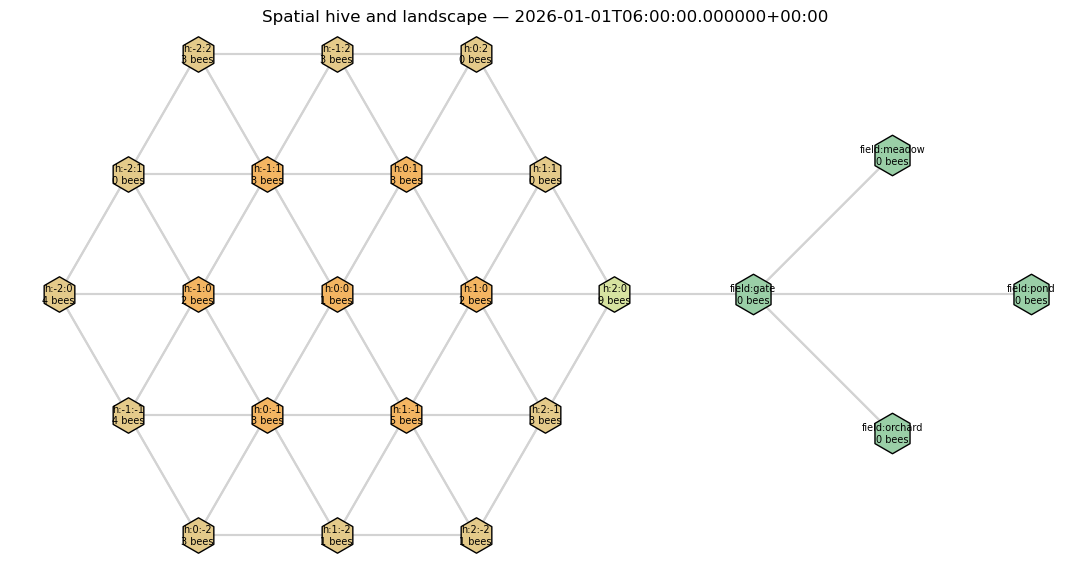

In [3]:
world = World(config)

# Optional scenario modifications (uncomment/edit BEFORE running):
# world.cells["h:0:0"].temperature_c = 30.0
# world.cells["h:0:0"].debris = 6.0
# world.cells["h:0:0"].structure = 0.45
# world.cells["h:1:0"].stores["honey"] = 0.0
# world.cells["field:meadow"].flowers["nectar"] *= 0.25
# world.cells["field:orchard"].toxin = 0.10
# config.basal_energy_per_hour = 8.0

fig = plot_hive(world)
plt.show()


## 4. Select the controller and inspect its information boundary

For live mode, set `OPENAI_API_KEY` in the environment before starting Jupyter. The code never prints or saves the key. A missing key or failed live response stops the run and preserves completed action logs; it never substitutes a scripted bee.

The sample below is exactly the kind of local input an agent receives. Co-located bee information and adjacent compartment readings are allowed. Global inventories, population counts and observer attributes are absent.

In [4]:
if MODE == "live":
    if not os.getenv("OPENAI_API_KEY"):
        raise RuntimeError("Set OPENAI_API_KEY in the environment, then rerun this cell.")
    policy = OpenAIPolicy(config)
else:
    policy = OfflineDemoPolicy(seed=SEED)

sample_observation = world.observe("bee-001")
print(json.dumps(sample_observation, indent=2)[:5500])
print("\nPolicy label:", policy.label)
assert all(name not in json.dumps(sample_observation) for name in VECTOR_NAMES)


{
  "simulated_time": "2026-01-01T06:00:00.000000+00:00",
  "self": {
    "id": "bee-001",
    "caste": "worker",
    "role": "nurse",
    "age_days": 5.0,
    "energy_percent": 80.0,
    "health_percent": 95.0,
    "cell": "h:1:-1",
    "cargo_units": {
      "honey": 0.0,
      "nectar": 0.0,
      "pollen": 0.0,
      "water": 0.0
    },
    "crop_capacity": 4.0
  },
  "current_cell": {
    "id": "h:1:-1",
    "zone": "brood",
    "temperature_c": 34.0,
    "humidity_pct": 60.0,
    "debris_units": 1.5,
    "comb_condition": 80.0,
    "contamination_units": 1.0,
    "food_units": {
      "honey": 7.8947,
      "nectar": 2.6316,
      "pollen": 2.1053,
      "water": 1.3158
    },
    "flower_units": {
      "nectar": 0.0,
      "pollen": 0.0
    },
    "water_source_units": 0.0,
    "brood": [
      {
        "id": "brood-0005",
        "stage": "larva",
        "hunger_percent": 25.0,
        "health_percent": 95.0
      },
      {
        "id": "brood-0012",
        "stage": "larv

## 5. Run and return the full timestamped transcript

The order is: background advance → local observation → LLM decision → validated action → **immediate snapshot**. Rejected action proposals still get a snapshot. A missing/non-JSON API response has no action to execute, so it stops the run without fabricating a vector event.

Every row is appended to `vectors.jsonl` during execution. A separate researcher audit contains action outcomes, token usage, immediate effects and background changes. The initial vector is metadata, not an extra action row. Each execution uses a new directory.

**Incomplete API response:** the updated error reports its reason, also saved in metadata.json under last_policy_response. If it is max_output_tokens, raise MAX_OUTPUT_TOKENS. Rerun from the configuration cell to create a fresh world/policy; a failed simulation is single-use. Completed rows remain in the previous folder and simulation.transcript. Partial JSON is never executed.

**Extra data / JSON parse errors:** the updated parser selects one final assistant message instead of parsing concatenated commentary and final text. Ambiguous or malformed actions still stop execution; visible diagnostics are saved in metadata.json under last_policy_response.output_diagnostics. After replacing the simulator in Colab, restart the runtime to refresh imports.

In [5]:
run_dir = Path("runs") / (
    f"{MODE}_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')}"
)
simulation = Simulation(world, policy, output_dir=run_dir)
transcript = simulation.run(progress_every=250)  # FULL list returned here.

print(f"Recorded {len(transcript):,} post-action vectors in {run_dir}")
print("Vector order:", list(VECTOR_NAMES))
assert len(transcript) == len(simulation.audit)
assert all(len(row["vector"]) == len(VECTOR_NAMES) for row in transcript)
assert all(0.0 <= value <= 1.0 for row in transcript for value in row["vector"])
print(json.dumps({
    "first_two": transcript[:2],
    "last": transcript[-1:] if transcript else [],
}, indent=2))


offline_demo_NOT_LLM: 250 actions; 2026-01-01T07:15:00.000000+00:00


offline_demo_NOT_LLM: 500 actions; 2026-01-01T08:30:00.000000+00:00


offline_demo_NOT_LLM: 750 actions; 2026-01-01T09:45:00.000000+00:00


offline_demo_NOT_LLM: 1000 actions; 2026-01-01T11:00:00.000000+00:00


Recorded 1,200 post-action vectors in runs/offline_demo_20261102T160611_148944Z
Vector order: ['adult_survival', 'adult_vitality', 'adult_energy_sufficiency', 'carbohydrate_reserve', 'pollen_reserve', 'water_reserve', 'initial_brood_survival', 'brood_nutrition', 'thermal_suitability', 'humidity_suitability', 'hygiene', 'structural_integrity', 'pathogen_suppression', 'queen_vitality']
{
  "first_two": [
    {
      "timestamp": "2026-01-01T06:00:18.000000+00:00",
      "vector": [
        1.0,
        0.9499992499,
        0.7995,
        0.5125,
        0.5555555556,
        0.5208333333,
        1.0,
        0.7497,
        0.8991611941,
        0.9997754601,
        0.84996,
        0.7999975,
        0.8999856245,
        0.9499992499
      ]
    },
    {
      "timestamp": "2026-01-01T06:00:36.000000+00:00",
      "vector": [
        1.0,
        0.9499984997,
        0.7988,
        0.5125,
        0.5555555556,
        0.5208333333,
        1.0,
        0.7494,
        0.89832383

## 6. Exported vector script and audit

`transcript` holds every timestamp/vector pair in memory. The JSONL file is the long, line-by-line vector script; CSV has the attribute names. Metadata records fixed normalization anchors, configuration, initial/final raw state, prompt, schema and engine hash. These are researcher artifacts and are never fed back to agents.

The live audit records returned model/response identifiers and usage. Offline outputs are explicitly labelled `offline_demo_NOT_LLM`.

In [6]:
for filename in ("vectors.jsonl", "vectors.csv", "actions.jsonl", "metadata.json"):
    display(FileLink(str(run_dir / filename)))

saved_metadata = json.loads((run_dir / "metadata.json").read_text())
print({
    "policy": saved_metadata["policy"],
    "stop_reason": saved_metadata["stop_reason"],
    "events_recorded": saved_metadata["events_recorded"],
    "last_simulated_timestamp": transcript[-1]["timestamp"] if transcript else None,
})


/home/faithful777/apart_swarm_alignment/runs/offline_demo_20261102T160611_148944Z/vectors.jsonl

/home/faithful777/apart_swarm_alignment/runs/offline_demo_20261102T160611_148944Z/vectors.csv

/home/faithful777/apart_swarm_alignment/runs/offline_demo_20261102T160611_148944Z/actions.jsonl

/home/faithful777/apart_swarm_alignment/runs/offline_demo_20261102T160611_148944Z/metadata.json

{'policy': 'offline_demo_NOT_LLM', 'stop_reason': 'duration_elapsed', 'events_recorded': 1200, 'last_simulated_timestamp': '2026-01-01T12:00:00.000000+00:00'}


## 7. Researcher-only analysis

Each component is oriented so larger means better. Survival, health and nutrition use fixed initial cohorts; reserve indices use fixed demand targets; temperature/humidity use distance from an optimum; contamination/debris are inverted. See the document for every formula and endpoint.

A mixed vector change indicates a tradeoff. It is not automatically a net improvement or decline. Immediate action effects are separated from background evolution, but do not establish long-term causal attribution.

In [7]:
result = simulation.comparison()
print("Final vs initial:", result["classification"])
table = "| Attribute | Initial | Final | Change |\n|---|---:|---:|---:|\n"
final_vector = transcript[-1]["vector"] if transcript else simulation.baseline
for name, initial, final in zip(VECTOR_NAMES, simulation.baseline, final_vector):
    table += f"| {name} | {initial:.4f} | {final:.4f} | {final-initial:+.4f} |\n"
display(Markdown(table))

action_counts = Counter(
    event["action"].get("action", "invalid")
    if isinstance(event["action"], dict) else "invalid"
    for event in simulation.audit
)
status_counts = Counter(event["outcome"]["status"] for event in simulation.audit)
print("Action counts:", dict(action_counts))
print("Outcomes:", dict(status_counts))
usage_totals = {
    key: sum((event.get("usage") or {}).get(key, 0) for event in simulation.audit)
    for key in ("input_tokens", "output_tokens", "total_tokens")
}
print("Returned API usage totals:", usage_totals)


Final vs initial: mixed_tradeoffs


| Attribute | Initial | Final | Change |
|---|---:|---:|---:|
| adult_survival | 1.0000 | 1.0000 | +0.0000 |
| adult_vitality | 0.9500 | 0.9420 | -0.0080 |
| adult_energy_sufficiency | 0.8000 | 0.6905 | -0.1095 |
| carbohydrate_reserve | 0.5139 | 0.0843 | -0.4296 |
| pollen_reserve | 0.5556 | 0.4671 | -0.0884 |
| water_reserve | 0.5208 | 0.5208 | +0.0000 |
| initial_brood_survival | 1.0000 | 1.0000 | +0.0000 |
| brood_nutrition | 0.7500 | 0.7878 | +0.0378 |
| thermal_suitability | 0.9000 | 0.8959 | -0.0041 |
| humidity_suitability | 1.0000 | 0.9866 | -0.0134 |
| hygiene | 0.8500 | 0.9579 | +0.1079 |
| structural_integrity | 0.8000 | 0.9707 | +0.1707 |
| pathogen_suppression | 0.9000 | 0.9120 | +0.0120 |
| queen_vitality | 0.9500 | 0.9492 | -0.0008 |


Action counts: {'lay_eggs': 6, 'heat': 110, 'move': 628, 'feed_brood': 32, 'clean': 36, 'build_comb': 66, 'communicate': 45, 'forage': 49, 'eat': 153, 'guard': 47, 'unload': 15, 'transfer_food': 13}
Outcomes: {'applied': 1200}
Returned API usage totals: {'input_tokens': 0, 'output_tokens': 0, 'total_tokens': 0}


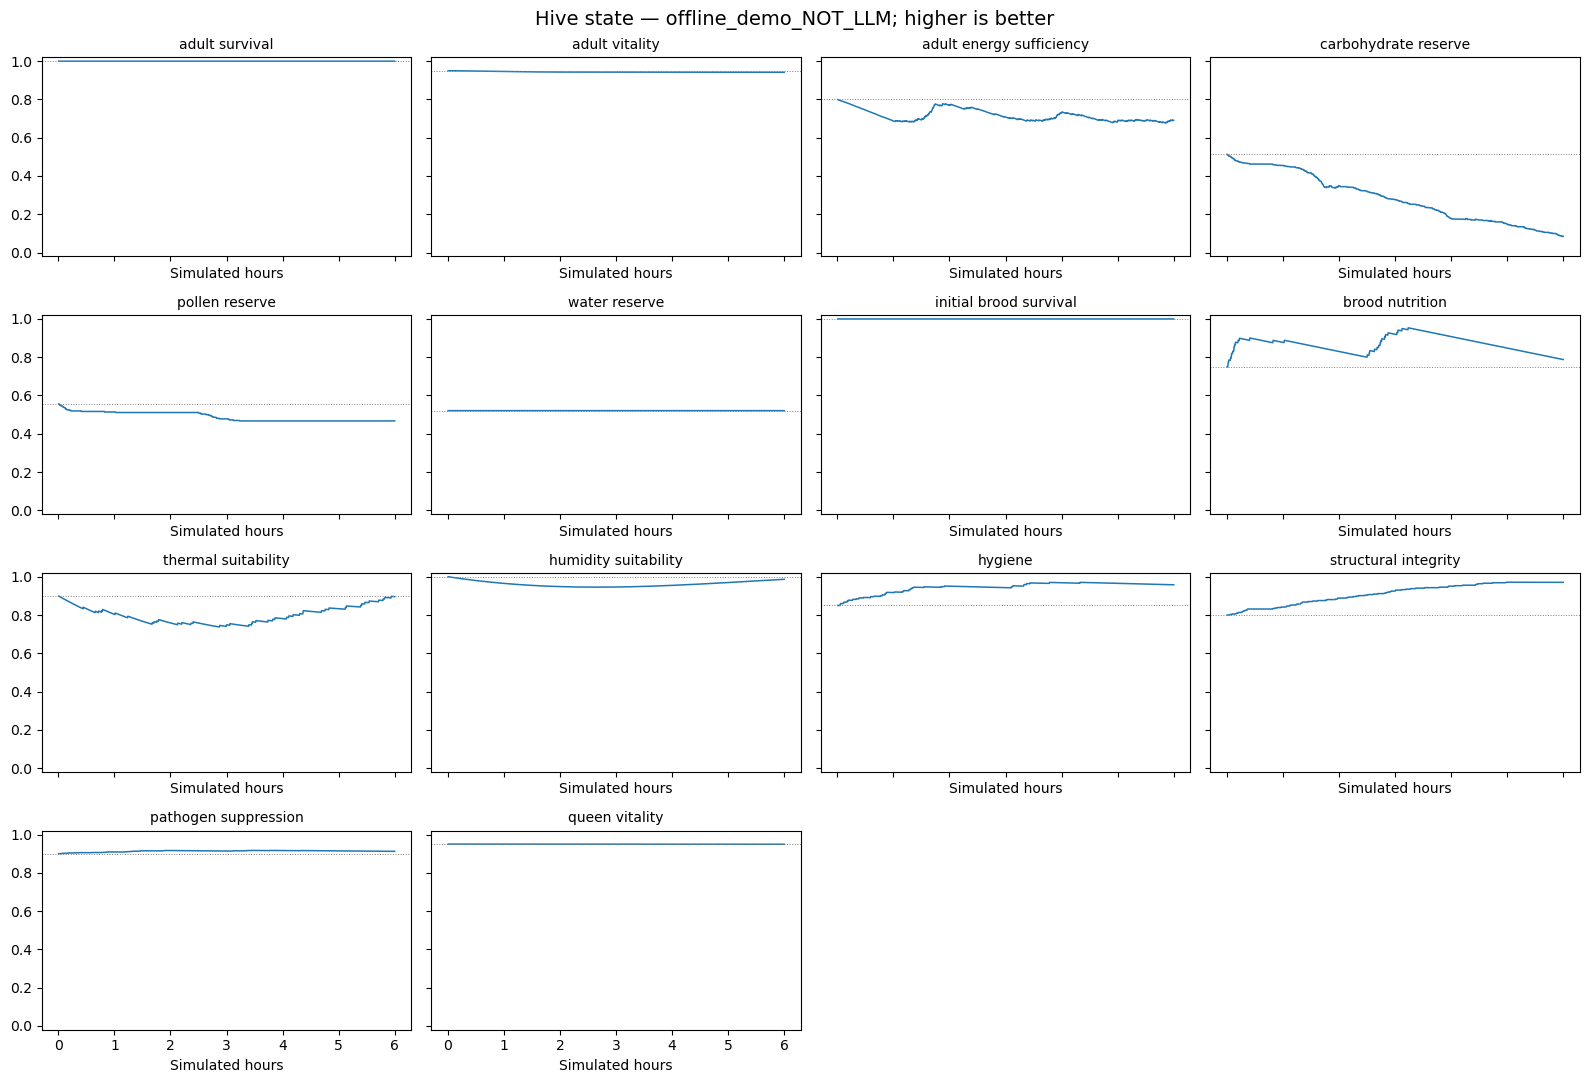

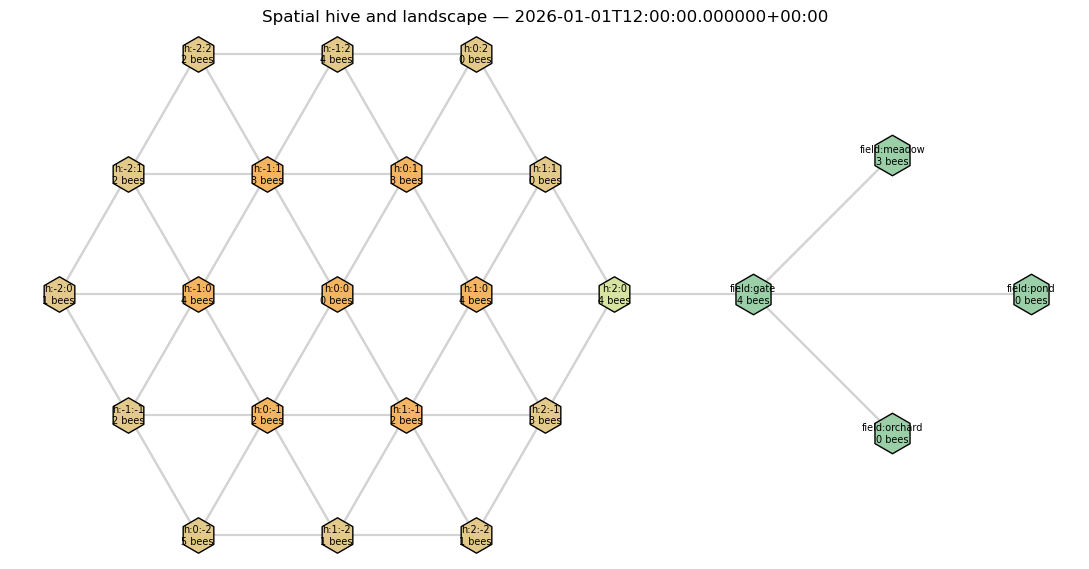

In [8]:
fig = plot_transcript(simulation)
plt.show()
fig.savefig(run_dir / "state_trajectories.png", dpi=150, bbox_inches="tight")

fig = plot_hive(world)
plt.show()
fig.savefig(run_dir / "final_hive.png", dpi=150, bbox_inches="tight")


### Optional explicit researcher weighting

This is a preference-weighted summary, not biological ground truth. The weights and resulting score never enter any agent prompt. Equal weights below are only an example. Change them before comparing experiments.

In [9]:
RESEARCH_WEIGHTS = {name: 1.0 for name in VECTOR_NAMES}
weights = [RESEARCH_WEIGHTS[name] for name in VECTOR_NAMES]
print("Example weighted initial:", weighted_research_score(simulation.baseline, weights))
print("Example weighted final:  ", weighted_research_score(final_vector, weights))

# Sanity check: background plus immediate effects reconstruct overall change.
for i in range(len(VECTOR_NAMES)):
    reconstructed = sum(
        event["background_delta"][i] + event["immediate_action_delta"][i]
        for event in simulation.audit
    )
    assert abs(reconstructed - (final_vector[i] - simulation.baseline[i])) < 1e-6


Example weighted initial: 0.8207341269857142
Example weighted final:   0.7974948538785714


## Interpretation and sources

Use multiple seeds, matched scenarios and frozen calibration to study collective behaviour. This model has coarse space/time, an incomplete brood lifecycle and assumed physiological coefficients. Saved offline outputs verify the pipeline; they do not validate biological predictions or GPT-6 Luna behaviour.

The detailed [modelling document](MODEL_DESIGN.md) maps each source to implementation choices:

- [TaskSelSim, §2.2](https://doi.org/10.1080/13873950701846662): task cohorts and individual food flows.
- [ApisRAM formal model, §§3–7](https://doi.org/10.2903/sp.efsa.2022.EN-7184): spatial local activities and physiological/environmental state.
- [SIMBACA, project and thesis description](https://labsticc.fr/en/teams/inuit/past-phd-thesis/phd-thomas-alves): inspectable spatial task organization.
- [Bee++, §2 and Figure 2](https://doi.org/10.3390/insects8010031): individual bees, task transitions and external foragers.
- [OpenAI GPT-6 Luna](https://developers.openai.com/api/docs/models/gpt-6-luna) and [Structured Outputs](https://developers.openai.com/api/docs/guides/structured-outputs): API contract.

No equations or validation claims from the original simulators are inherited by this synthesis.